# Final Project Reproduce Plot

Since I ran this on the Google Colaboratory, and all related files are upload on that as temporary, so you might not be able to directly use it, this is just showing the reproduce result, all the related files are stored in the folder "fg1_result", "fg2_result", and "fg3_result".

## Plot algorithm


In [112]:

from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


COLORS = ["red", "blue", "green", "cyan",
          "magenta", "orange", "purple", "brown"]

LINESTYLES = ["-", "--", "-."]

# Read a training log and return its numerical records as a DataFrame.
# Parameters：
# ----------
# 'filename' : str
#     Path to the training log.
#     The '.txt' extension is optional.
#     Supports UTF-8 and UTF-16 encoded text files.
# Returns
# -------
# pandas.DataFrame
#     DataFrame containing iteration and all recorded metrics.
def read_log(filename):
    path = Path(filename)

    if path.suffix.lower() != ".txt":
        path = path.with_suffix(".txt")

    with open(path, "rb") as f:
        raw = f.read()

    if raw.startswith((b"\xff\xfe", b"\xfe\xff")):
        text = raw.decode("utf-16")
    else:
        text = raw.decode("utf-8-sig")

    pattern = re.compile(
        r"([A-Za-z_]\w*)\s*:\s*"
        r"([-+]?(?:\d+\.?\d*|\.\d+)(?:[eE][-+]?\d+)?)"
    )

    records = []

    for line in text.splitlines():
        values = {
            key: float(value)
            for key, value in pattern.findall(line)
        }

        if "iteration" in values:
            records.append(values)

    if not records:
        raise ValueError(f"No training data found: {filename}")

    return pd.DataFrame(records)


# Configure the common appearance of a plot.
# Parameters
# ----------
# 'ax' : matplotlib.axes.Axes
#     The axes to configure.

# 'figure_title' : str
#     Title displayed above the plot.

# 'ylabel' : str
#     Label displayed on the vertical axis.

# Returns
# -------
# None
def setup_plot(ax, figure_title, ylabel):
  ax.set_title(figure_title)
  ax.set_xlabel("iteration")
  ax.set_ylabel(ylabel)
  ax.grid(True, alpha=0.25)

  ax.ticklabel_format(
      style="sci",
      axis="x",
      scilimits=(0, 0)
  )

# Save the plot as a PNG file and display it.

# Parameters
# ----------
# 'fig' : matplotlib.figure.Figure
#     Figure to save.

# 'figure_title' : str
#     Title used to generate the PNG filename.
#     Unsupported filename characters are replaced by '_'.

# Returns
# -------
# None
# """
def save_plot(fig, figure_title):
    fig.tight_layout()

    filename = re.sub(
        r"[^\w.-]+", "_", figure_title
    )

    fig.savefig(filename + ".png", dpi=220)
    plt.show()


# Plot one metric from any number of training log files.
# Each file is represented by one solid line with a
# different color.
# Parameters
# ----------
# 'filename_list' : list[str]
#     List of training log filenames.
#     Files are plotted in the given order.
#     The number of files is not fixed.

# 'display_properties' : str
#     Name of the metric to plot.
#     Example: "test_RMSE", "erank", "full_MSE".

# 'figure_title' : str
#     Title of the figure and basis for the PNG filename.

# 'legend_name' : str, optional
#     Title of the legend.
#     Example: "depth", "lambda", "optimizer".

# 'legend_arms_name' : list[str], optional
#     Labels for the files, in the same order as filename_list.
#     Must contain one label per file.
#     If None, the filenames are used as labels.

# Returns
# -------
# 'fig' : matplotlib.figure.Figure
#     Created figure.

# 'ax' : matplotlib.axes.Axes
#     Created axes.
def my_plot(
    filename_list,
    display_properties,
    figure_title,
    legend_name="Legend",
    legend_arms_name=None
):
    if not filename_list:
        raise ValueError("filename_list cannot be empty")

    if legend_arms_name is None:
        legend_arms_name = [
            Path(f).stem for f in filename_list
        ]

    if len(legend_arms_name) != len(filename_list):
        raise ValueError(
            "legend_arms_name must have one label per file"
        )

    fig, ax = plt.subplots(figsize=(7, 4.5))

    for i, filename in enumerate(filename_list):
        df = read_log(filename)

        if display_properties not in df.columns:
            raise ValueError(
                f"Metric '{display_properties}' "
                f"not found in {filename}"
            )

        color = COLORS[i % len(COLORS)]

        ax.plot(
            df["iteration"],
            df[display_properties],
            color=color,
            linestyle="-",
            linewidth=1.5,
            label=str(legend_arms_name[i])
        )

    setup_plot(
        ax,
        figure_title,
        display_properties
    )

    ax.legend(
        title=legend_name,
        loc="best"
    )

    save_plot(fig, figure_title)

    return fig, ax

# Plot 2 or 3 metrics from any number of training log files.
# Each file has a unique color.
# Metrics from the same file share that color but use
# different line styles.
# Line styles:
#     First metric  : solid (-)
#     Second metric : dashed (--)
#     Third metric  : dash-dot (-.)
# Two separate legends are displayed:
#     Legend 1: File identity -> color
#     Legend 2: Metric identity -> line style
# Parameters
# ----------
# 'filename_list' : list[str]
#     List of training log filenames.
#     Files are plotted in the given order.
#     The number of files is not fixed.

# 'display_properties' : tuple[str, ...]
#     Tuple containing exactly 2 or 3 metric names.
#     Example: ("sv1", "sv5")
#     Example: ("sv1", "sv5", "sv6")

# 'figure_title' : str
#     Title of the figure and basis for the PNG filename.

# 'legend_name' : list[str], optional
#     Titles of the two legends.
#     Must contain exactly two strings.

#     Example: ["depth", "S.V."]

#     legend_name[0] names the color legend.
#     legend_name[1] names the line-style legend.

# 'legend_arms_name' : list[list[str]], optional
#     Two-dimensional list of legend labels.

#     First inner list:
#         Labels for files/colors, in filename_list order.
#         Must have the same length as filename_list.

#     Second inner list:
#         Labels for metrics/line styles, in
#         display_properties order.
#         Must have the same length as display_properties.

#     Example:
#         [
#             ["2", "3", "4", "5"],
#             ["1st", "5th", "6th"]
#         ]

#     If None, filenames and metric names are used.
# Returns
# -------
# 'fig' : matplotlib.figure.Figure
#     Created figure.

# 'ax' : matplotlib.axes.Axes
#     Created axes.
def my_plot_pair(
    filename_list,
    display_properties,
    figure_title,
    legend_name=None,
    legend_arms_name=None
):
    if not filename_list:
        raise ValueError("filename_list cannot be empty")

    if not isinstance(display_properties, tuple):
        raise ValueError(
            "display_properties must be a tuple"
        )

    if len(display_properties) not in (2, 3):
        raise ValueError(
            "display_properties must contain 2 or 3 metrics"
        )

    if legend_name is None:
        legend_name = ["Files", "Metrics"]

    if len(legend_name) != 2:
        raise ValueError(
            "legend_name must contain exactly 2 titles"
        )

    if legend_arms_name is None:
        legend_arms_name = [
            [Path(f).stem for f in filename_list],
            list(display_properties)
        ]

    if (
        len(legend_arms_name) != 2
        or len(legend_arms_name[0]) != len(filename_list)
        or len(legend_arms_name[1]) != len(display_properties)
    ):
        raise ValueError(
            "legend_arms_name must contain two lists: "
            "one label per file and one label per metric"
        )

    fig, ax = plt.subplots(figsize=(7, 4.5))

    for i, filename in enumerate(filename_list):
        df = read_log(filename)
        color = COLORS[i % len(COLORS)]

        for j, metric in enumerate(display_properties):
            if metric not in df.columns:
                raise ValueError(
                    f"Metric '{metric}' not found in {filename}"
                )

            ax.plot(
                df["iteration"],
                df[metric],
                color=color,
                linestyle=LINESTYLES[j],
                linewidth=1.5
            )

    setup_plot(ax, figure_title, "magnitude")

    # Legend 1: file identity -> color
    file_handles = [
        Line2D(
            [0], [0],
            color=COLORS[i % len(COLORS)],
            linestyle="-",
            lw=1.5,
            label=str(legend_arms_name[0][i])
        )
        for i in range(len(filename_list))
    ]

    legend1 = ax.legend(
        handles=file_handles,
        title=legend_name[0],
        loc="upper left",
        bbox_to_anchor=(1.02, 1)
    )

    ax.add_artist(legend1)

    # Legend 2: metric identity -> line style
    metric_handles = [
        Line2D(
            [0], [0],
            color="black",
            linestyle=LINESTYLES[j],
            lw=1.5,
            label=str(legend_arms_name[1][j])
        )
        for j in range(len(display_properties))
    ]

    ax.legend(
        handles=metric_handles,
        title=legend_name[1],
        loc="upper left",
        bbox_to_anchor=(1.02, 0.62)
    )

    save_plot(fig, figure_title)

    return fig, ax


## figure 1: use the Mean SSE for the training

In [120]:
fg1_GD_list_11 = ["./fg1_result/fg1_GD_depth2","./fg1_result/fg1_GD_depth3","./fg1_result/fg1_GD_depth4","./fg1_result/fg1_GD_depth5",]
fg1_Adam_list_11 = ["./fg1_result/fg1_Adam_depth2","./fg1_result/fg1_Adam_depth3","./fg1_result/fg1_Adam_depth4","./fg1_result/fg1_Adam_depth5",]



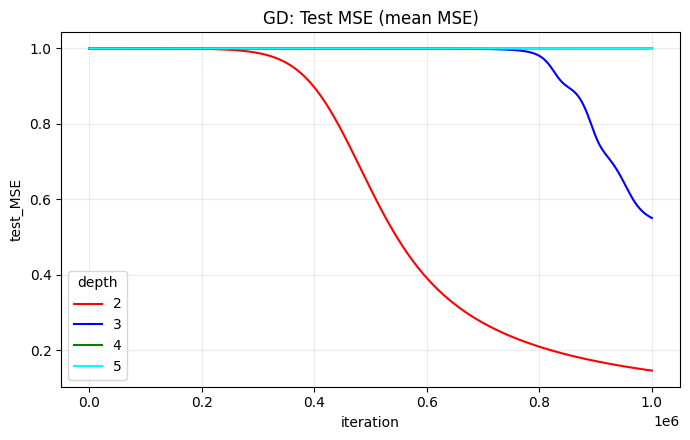

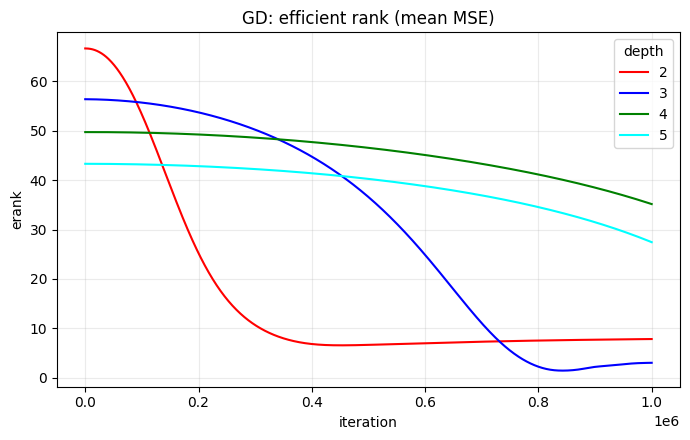

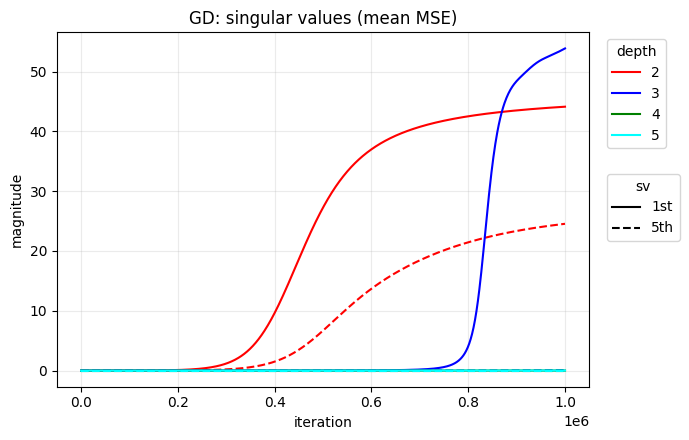

(<Figure size 700x450 with 1 Axes>,
 <Axes: title={'center': 'GD: singular values (mean MSE)'}, xlabel='iteration', ylabel='magnitude'>)

In [121]:
fg12_legend_name = ["depth","sv"]
fg12_legend_arms_name = [["2", "3", "4", "5"],["1st", "5th"]]


my_plot(
    filename_list = fg1_GD_list_11,
    display_properties = "test_MSE",
    figure_title ="GD: Test MSE (mean MSE)",
    legend_name = fg12_legend_name[0],
    legend_arms_name = fg12_legend_arms_name[0]
    )
my_plot(
    filename_list = fg1_GD_list_11,
    display_properties = "erank",
    figure_title = "GD: efficient rank (mean MSE)",
    legend_name = fg12_legend_name[0],
    legend_arms_name = fg12_legend_arms_name[0])

my_plot_pair(
    filename_list=fg1_GD_list_11,
    display_properties=("sv1", "sv5"),
    figure_title="GD: singular values (mean MSE)",
    legend_name = fg12_legend_name,
    legend_arms_name=fg12_legend_arms_name)



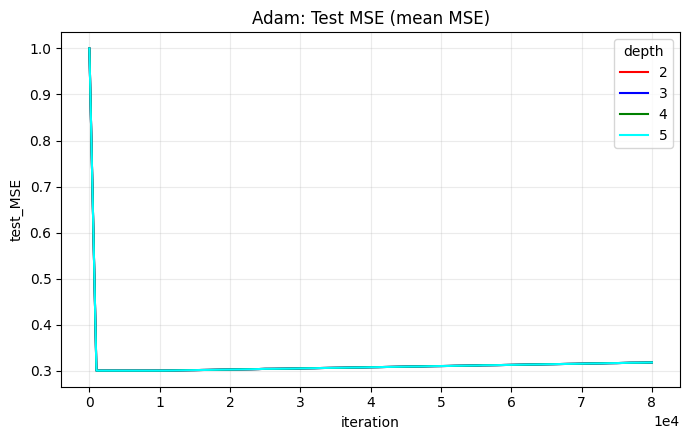

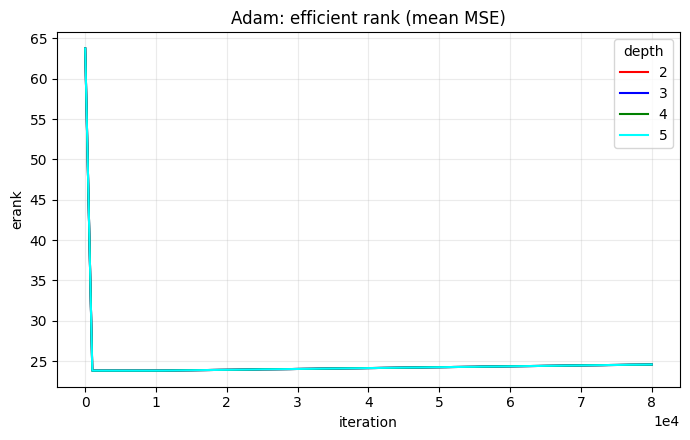

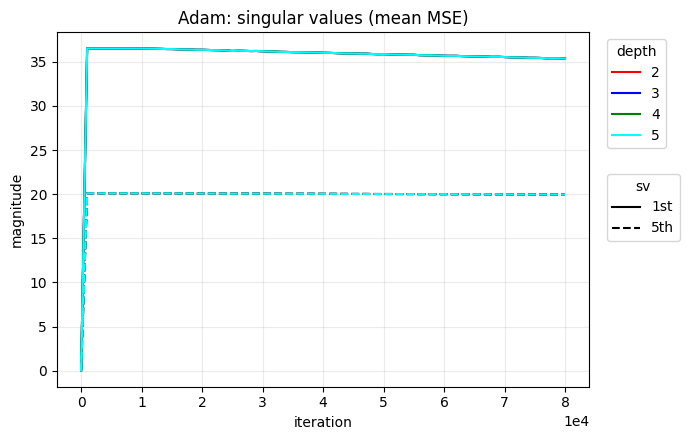

(<Figure size 700x450 with 1 Axes>,
 <Axes: title={'center': 'Adam: singular values (mean MSE)'}, xlabel='iteration', ylabel='magnitude'>)

In [101]:

my_plot(
    filename_list = fg1_Adam_list_11,
    display_properties = "test_MSE",
    figure_title ="Adam: Test MSE (mean MSE)",
    legend_name = fg12_legend_name[0],
    legend_arms_name = fg12_legend_arms_name[0]
    )
my_plot(
    filename_list = fg1_Adam_list_11,
    display_properties = "erank",
    figure_title = "Adam: efficient rank (mean MSE)",
    legend_name = fg12_legend_name[0],
    legend_arms_name = fg12_legend_arms_name[0]
    )

my_plot_pair(
    filename_list=fg1_Adam_list_11,
    display_properties=("sv1", "sv5"),
    figure_title="Adam: singular values (mean MSE)",
    legend_name = fg12_legend_name,
    legend_arms_name=fg12_legend_arms_name
    )

## figure2: use mean SSE for training model

In [117]:
fg2_GD_list_21 = ["./fg2_result/fg2_GD_depth2","./fg2_result/fg2_GD_depth3","./fg2_result/fg2_GD_depth4","./fg2_result/fg2_GD_depth5",]
fg2_Adam_list_21 = ["./fg2_result/fg2_Adam_depth2","./fg2_result/fg2_Adam_depth3","./fg2_result/fg2_Adam_depth4","./fg2_result/fg2_Adam_depth5",]


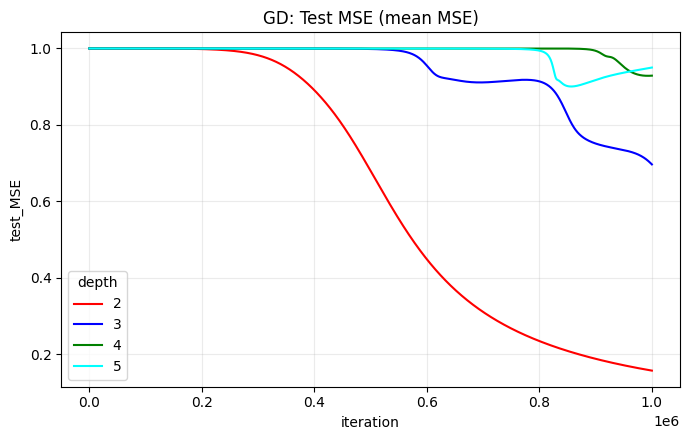

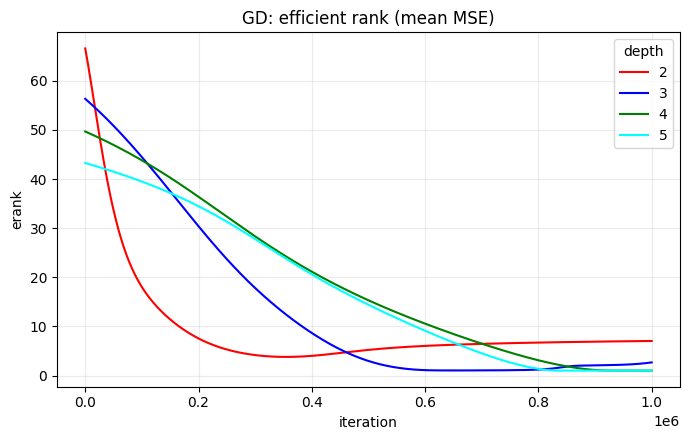

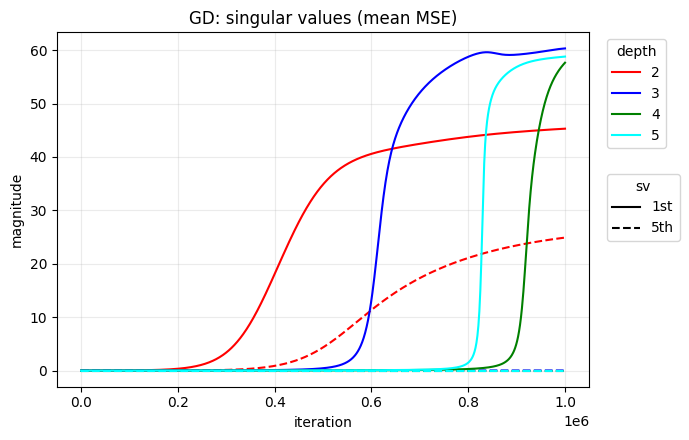

(<Figure size 700x450 with 1 Axes>,
 <Axes: title={'center': 'GD: singular values (mean MSE)'}, xlabel='iteration', ylabel='magnitude'>)

In [118]:
my_plot(
    filename_list = fg2_GD_list_21,
    display_properties = "test_MSE",
    figure_title ="GD: Test MSE (mean MSE)",
    legend_name = fg12_legend_name[0],
    legend_arms_name = fg12_legend_arms_name[0]
    )
my_plot(
    filename_list = fg2_GD_list_21,
    display_properties = "erank",
    figure_title = "GD: efficient rank (mean MSE)",
    legend_name = fg12_legend_name[0],
    legend_arms_name = fg12_legend_arms_name[0]
    )

my_plot_pair(
    filename_list=fg2_GD_list_21,
    display_properties=("sv1", "sv5"),
    figure_title="GD: singular values (mean MSE)",
    legend_name = fg12_legend_name,
    legend_arms_name=fg12_legend_arms_name
    )



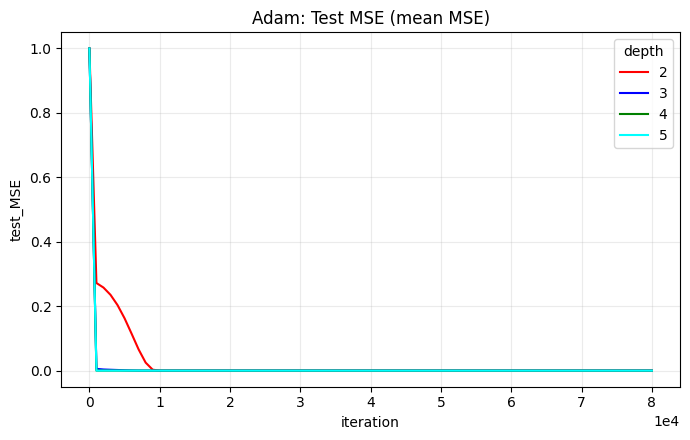

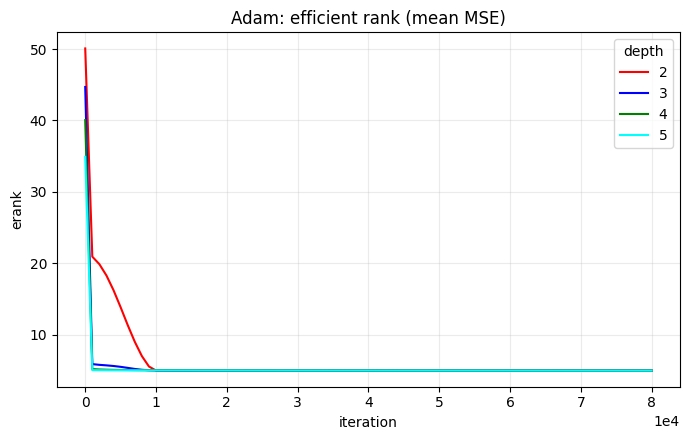

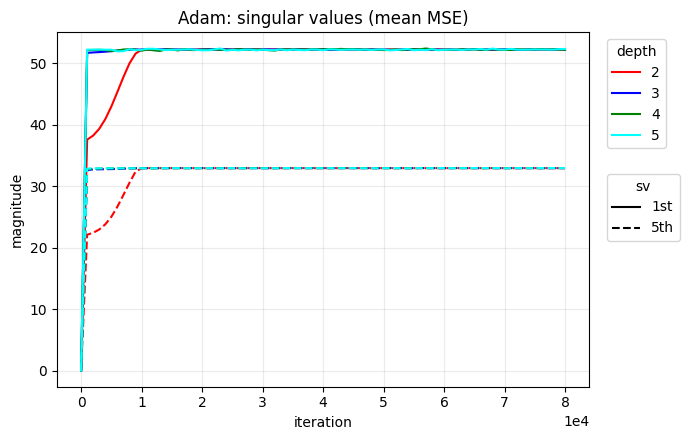

(<Figure size 700x450 with 1 Axes>,
 <Axes: title={'center': 'Adam: singular values (mean MSE)'}, xlabel='iteration', ylabel='magnitude'>)

In [119]:
my_plot(
    filename_list = fg2_Adam_list_21,
    display_properties = "test_MSE",
    figure_title ="Adam: Test MSE (mean MSE)",
    legend_name = fg12_legend_name[0],
    legend_arms_name = fg12_legend_arms_name[0]
    )
my_plot(
    filename_list = fg2_Adam_list_21,
    display_properties = "erank",
    figure_title = "Adam: efficient rank (mean MSE)",
    legend_name = fg12_legend_name[0],
    legend_arms_name = fg12_legend_arms_name[0]
    )

my_plot_pair(
    filename_list=fg2_Adam_list_21,
    display_properties=("sv1", "sv5"),
    figure_title="Adam: singular values (mean MSE)",
    legend_name = fg12_legend_name,
    legend_arms_name=fg12_legend_arms_name
    )

## figure 3

In [93]:
fg3_GD_list = ["./fg3_result/fg3_GD_lam0.txt","./fg3_result/fg3_GD_lam001.txt",]
fg3_Adam_list = ["./fg3_result/fg3_Adam_lam0.txt","./fg3_result/fg3_Adam_lam001.txt",]

fg3_legend_name = ["lambda","sv"]
fg3_legend_arms_name = [["0", "0.1",],["1st", "5th","6th"]]

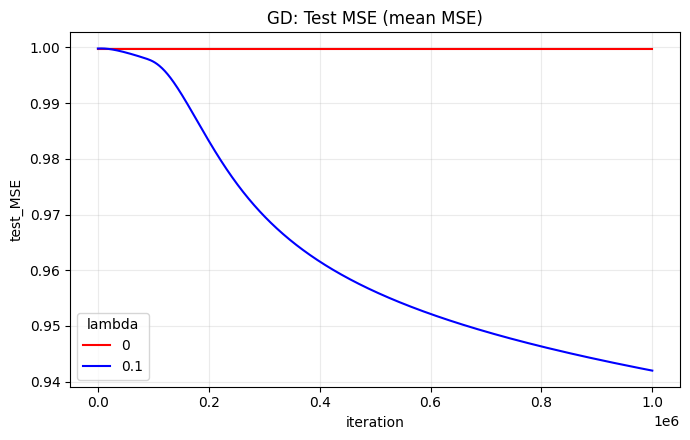

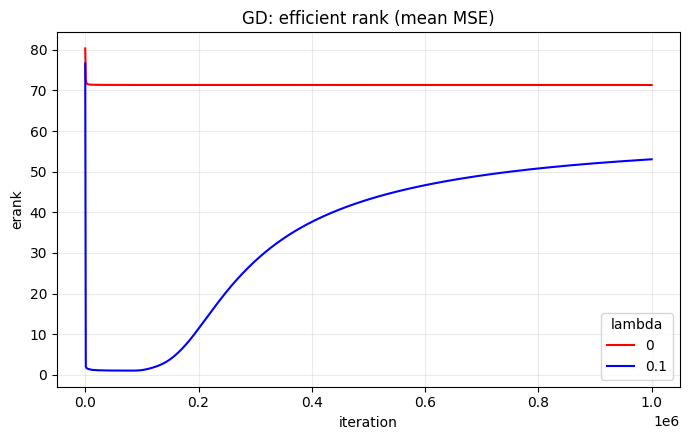

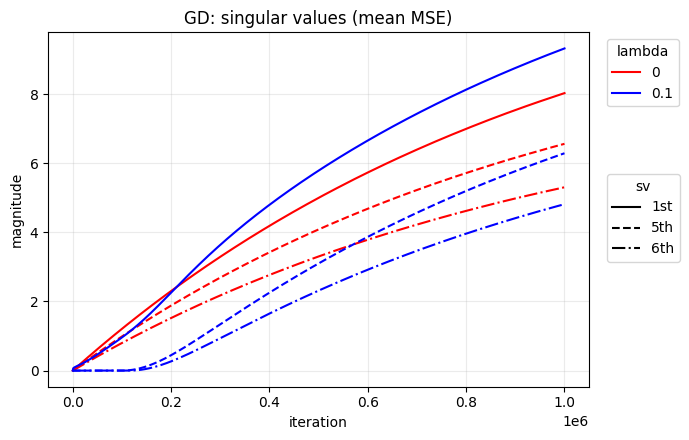

(<Figure size 700x450 with 1 Axes>,
 <Axes: title={'center': 'GD: singular values (mean MSE)'}, xlabel='iteration', ylabel='magnitude'>)

In [96]:

my_plot(
    filename_list = fg3_GD_list,
    display_properties = "test_MSE",
    figure_title ="GD: Test MSE (mean MSE)",
    legend_name = fg3_legend_name[0],
    legend_arms_name = fg3_legend_arms_name[0]
    )
my_plot(
    filename_list = fg3_GD_list,
    display_properties = "erank",
    figure_title = "GD: efficient rank (mean MSE)",
    legend_name = fg3_legend_name[0],
    legend_arms_name = fg3_legend_arms_name[0]
    )

my_plot_pair(
    filename_list=fg3_GD_list,
    display_properties=("sv1", "sv5", "sv6"),
    figure_title="GD: singular values (mean MSE)",
    legend_name = fg3_legend_name,
    legend_arms_name=fg3_legend_arms_name
    )


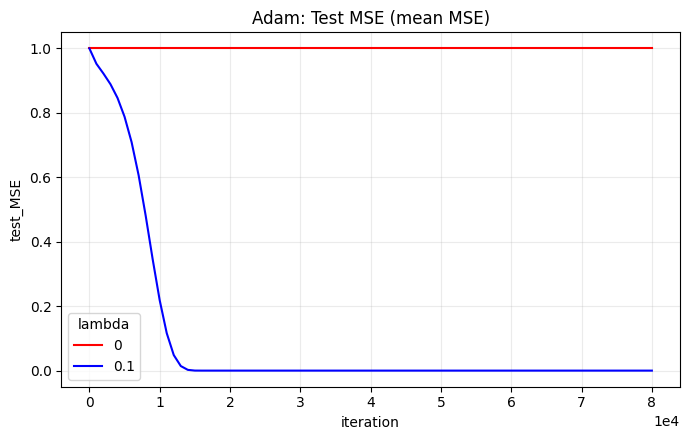

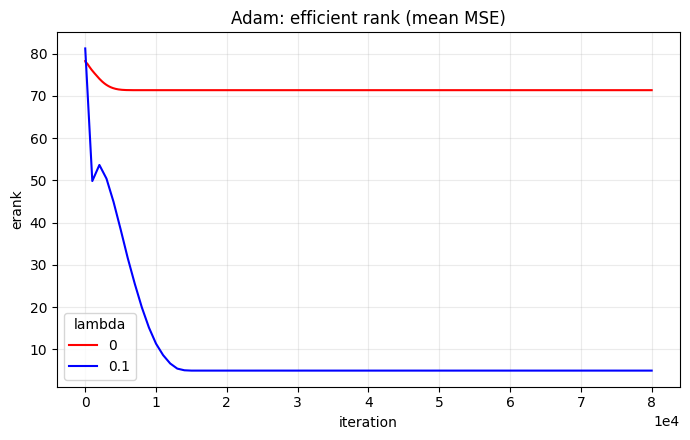

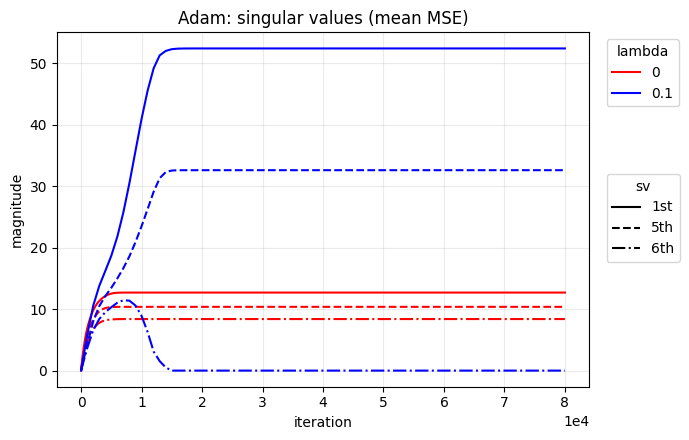

(<Figure size 700x450 with 1 Axes>,
 <Axes: title={'center': 'Adam: singular values (mean MSE)'}, xlabel='iteration', ylabel='magnitude'>)

In [97]:
my_plot(
    filename_list = fg3_Adam_list,
    display_properties = "test_MSE",
    figure_title ="Adam: Test MSE (mean MSE)",
    legend_name = fg3_legend_name[0],
    legend_arms_name = fg3_legend_arms_name[0]
    )
my_plot(
    filename_list = fg3_Adam_list,
    display_properties = "erank",
    figure_title = "Adam: efficient rank (mean MSE)",
    legend_name = fg3_legend_name[0],
    legend_arms_name = fg3_legend_arms_name[0]
    )

my_plot_pair(
    filename_list=fg3_Adam_list,
    display_properties=("sv1", "sv5", "sv6"),
    figure_title="Adam: singular values (mean MSE)",
    legend_name = fg3_legend_name,
    legend_arms_name=fg3_legend_arms_name
    )

# Unuseful experiment result

This is using the Sum SSE intead of Mean SSE. The reason why I provide this is that at the begining when I did the reproduce for the figure 1 and figure 2, the result is not same as the paper shows, so I changed the Sum SSE trying to see if this can be better, but the result shows is actually worse than mean SSE, so I just give it up

## figure 2: use sum SSE for the training model

In [115]:
fg2_GD_list_22 = ["./fg2_result_sum/fg2_GD_depth2","./fg2_result_sum/fg2_GD_depth3","./fg2_result_sum/fg2_GD_depth4","./fg2_result_sum/fg2_GD_depth5",]
fg2_Adam_list_22 = ["./fg2_result_sum/fg2_Adam_depth2","./fg2_result_sum/fg2_Adam_depth3","./fg2_result_sum/fg2_Adam_depth4","./fg2_result_sum/fg2_Adam_depth5",]


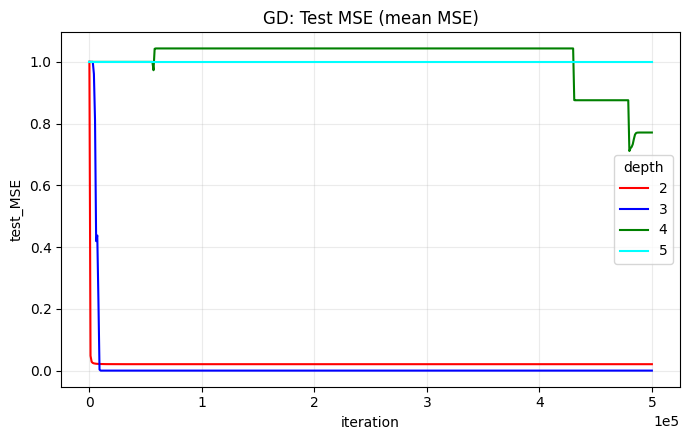

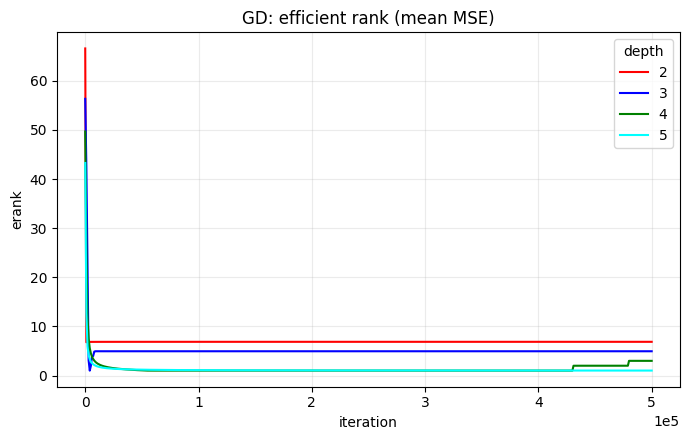

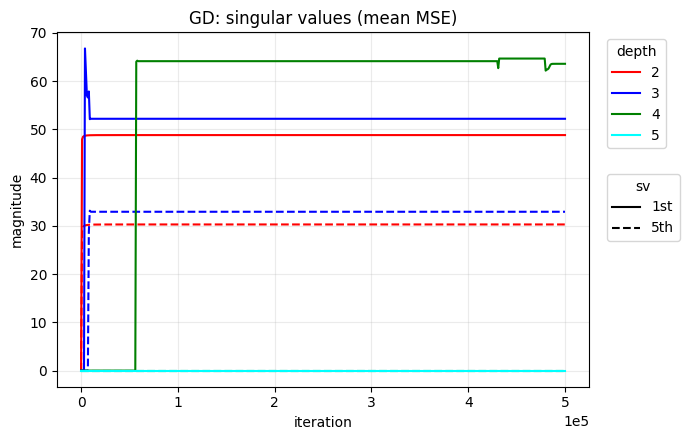

(<Figure size 700x450 with 1 Axes>,
 <Axes: title={'center': 'GD: singular values (mean MSE)'}, xlabel='iteration', ylabel='magnitude'>)

In [116]:
my_plot(
    filename_list = fg2_GD_list_22,
    display_properties = "test_MSE",
    figure_title ="GD: Test MSE (mean MSE)",
    legend_name = fg12_legend_name[0],
    legend_arms_name = fg12_legend_arms_name[0]
    )
my_plot(
    filename_list = fg2_GD_list_22,
    display_properties = "erank",
    figure_title = "GD: efficient rank (mean MSE)",
    legend_name = fg12_legend_name[0],
    legend_arms_name = fg12_legend_arms_name[0]
    )

my_plot_pair(
    filename_list=fg2_GD_list_22,
    display_properties=("sv1", "sv5"),
    figure_title="GD: singular values (mean MSE)",
    legend_name = fg12_legend_name,
    legend_arms_name=fg12_legend_arms_name
    )


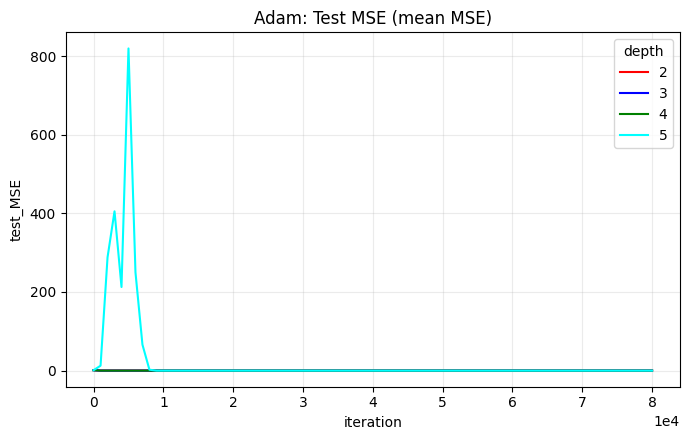

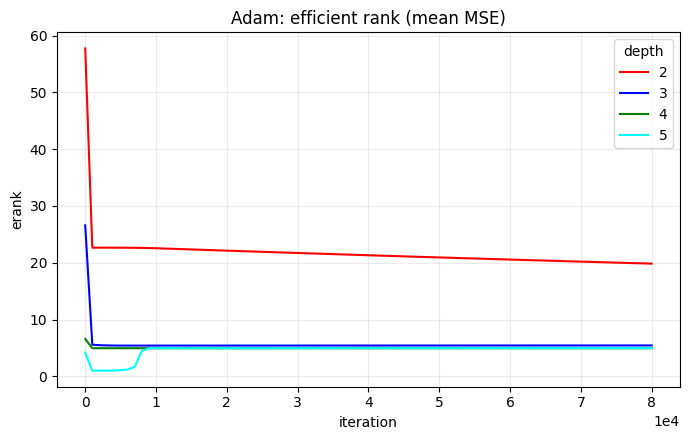

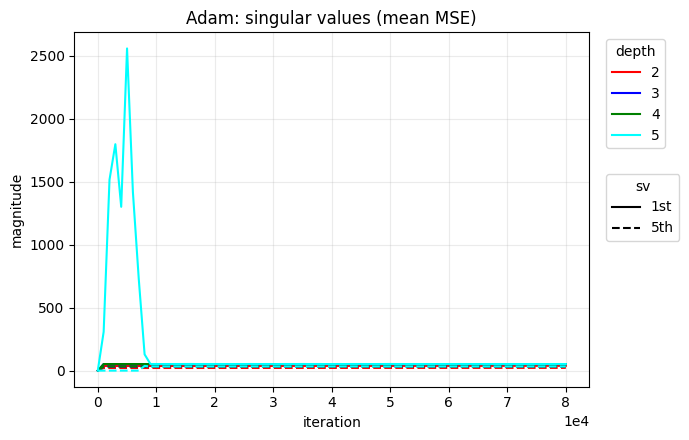

(<Figure size 700x450 with 1 Axes>,
 <Axes: title={'center': 'Adam: singular values (mean MSE)'}, xlabel='iteration', ylabel='magnitude'>)

In [111]:

my_plot(
    filename_list = fg2_Adam_list_22,
    display_properties = "test_MSE",
    figure_title ="Adam: Test MSE (mean MSE)",
    legend_name = fg12_legend_name[0],
    legend_arms_name = fg12_legend_arms_name[0]
    )
my_plot(
    filename_list = fg2_Adam_list_22,
    display_properties = "erank",
    figure_title = "Adam: efficient rank (mean MSE)",
    legend_name = fg12_legend_name[0],
    legend_arms_name = fg12_legend_arms_name[0]
    )

my_plot_pair(
    filename_list=fg2_Adam_list_22,
    display_properties=("sv1", "sv5"),
    figure_title="Adam: singular values (mean MSE)",
    legend_name = fg12_legend_name,
    legend_arms_name=fg12_legend_arms_name
    )

## figure 1: use sum for SSE for training model

In [103]:
fg1_GD_list_12 = ["./fg1_result_sum/fg1_GD_depth2","./fg1_result_sum/fg1_GD_depth3","./fg1_result_sum/fg1_GD_depth4","./fg1_result_sum/fg1_GD_depth5",]
fg1_Adam_list_12 = ["./fg1_result_sum/fg1_Adam_depth2","./fg1_result_sum/fg1_Adam_depth3","./fg1_result_sum/fg1_Adam_depth4","./fg1_result_sum/fg1_Adam_depth5",]


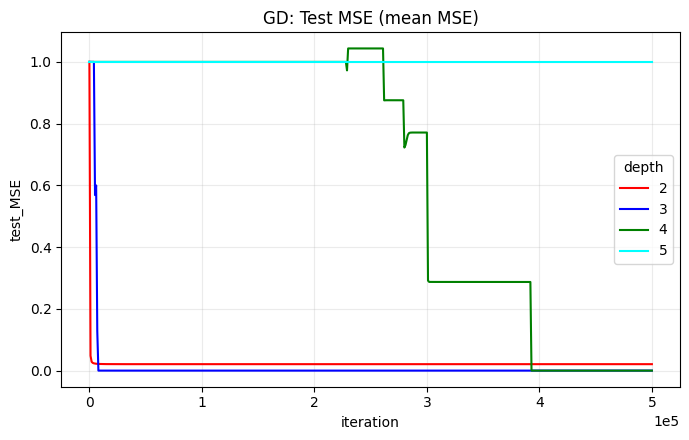

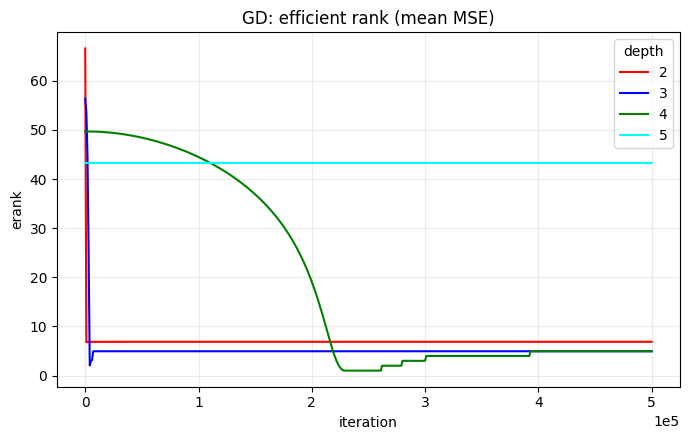

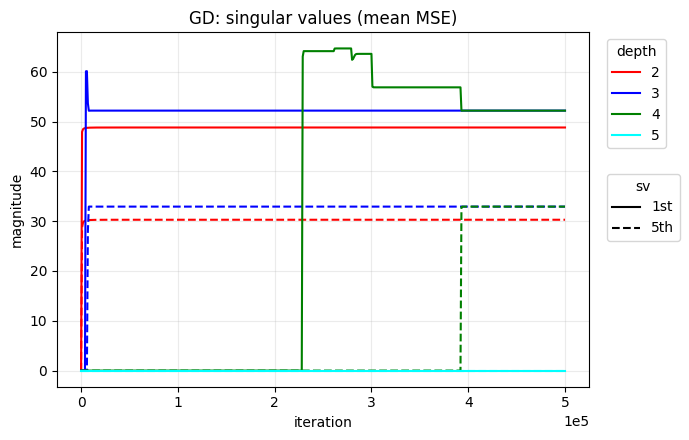

(<Figure size 700x450 with 1 Axes>,
 <Axes: title={'center': 'GD: singular values (mean MSE)'}, xlabel='iteration', ylabel='magnitude'>)

In [104]:
my_plot(
    filename_list = fg1_GD_list_12,
    display_properties = "test_MSE",
    figure_title ="GD: Test MSE (mean MSE)",
    legend_name = fg12_legend_name[0],
    legend_arms_name = fg12_legend_arms_name[0]
    )
my_plot(
    filename_list = fg1_GD_list_12,
    display_properties = "erank",
    figure_title = "GD: efficient rank (mean MSE)",
    legend_name = fg12_legend_name[0],
    legend_arms_name = fg12_legend_arms_name[0]
    )

my_plot_pair(
    filename_list=fg1_GD_list_12,
    display_properties=("sv1", "sv5"),
    figure_title="GD: singular values (mean MSE)",
    legend_name = fg12_legend_name,
    legend_arms_name=fg12_legend_arms_name
    )

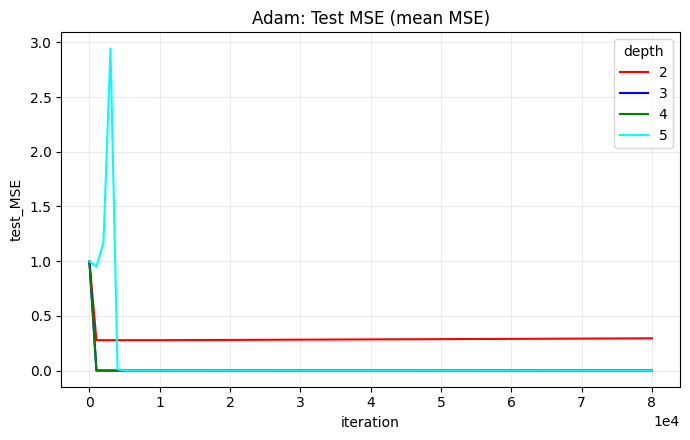

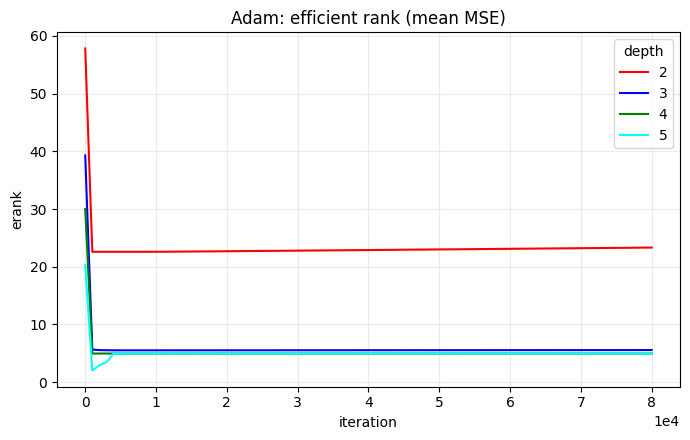

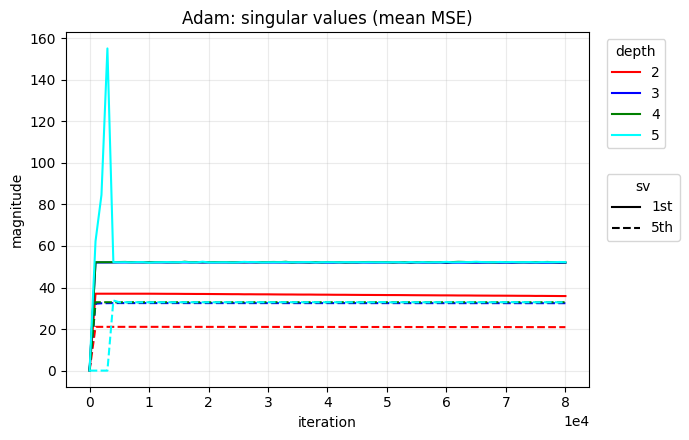

(<Figure size 700x450 with 1 Axes>,
 <Axes: title={'center': 'Adam: singular values (mean MSE)'}, xlabel='iteration', ylabel='magnitude'>)

In [105]:
my_plot(
    filename_list = fg1_Adam_list_12,
    display_properties = "test_MSE",
    figure_title ="Adam: Test MSE (mean MSE)",
    legend_name = fg12_legend_name[0],
    legend_arms_name = fg12_legend_arms_name[0]
    )
my_plot(
    filename_list = fg1_Adam_list_12,
    display_properties = "erank",
    figure_title = "Adam: efficient rank (mean MSE)",
    legend_name = fg12_legend_name[0],
    legend_arms_name = fg12_legend_arms_name[0]
    )

my_plot_pair(
    filename_list=fg1_Adam_list_12,
    display_properties=("sv1", "sv5"),
    figure_title="Adam: singular values (mean MSE)",
    legend_name = fg12_legend_name,
    legend_arms_name=fg12_legend_arms_name
    )